### Week 1 XAI

In [ ]:
#set path
import os, sys
from pathlib import Path

PROJECT = Path.cwd()
while not (PROJECT / "src").exists() and PROJECT != PROJECT.parent:
    PROJECT = PROJECT.parent                # walk up until we find the folder containing src/
os.chdir(PROJECT)                           # so data/... paths in src/ work
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))        # so "import src" works

from src.data import study_table, findings_texts, usable_findings, binary_label
from src.embeddings import embedding_path, load_embeddings

studies = study_table()
X = load_embeddings(embedding_path("findings"), studies)
print(X.shape)   # expect (10000, 768)



In [ ]:
from src.data import study_table, findings_texts, usable_findings, binary_label
from src.embeddings import embedding_path, load_embeddings

studies = study_table()
X = load_embeddings(embedding_path("findings"), studies)   # shape (10000, 768)

### Step 3


# **Steps**

De to sygdomme

Edema (lungeødem): væske i selve lungevævet. Det skyldes ofte, at hjertet ikke pumper godt nok (hjertesvigt), så væsken hober sig op i lungerne. På røntgen ses det som et sløret, “tåget” mønster i lungerne.
Pleural effusion (væske i lungehinden): væske uden for lungen, mellem lungen og brystvæggen. På røntgen ses det typisk som et hvidt område nederst, der udvisker den skarpe vinkel mellem lunge og mellemgulv.

Begge er almindelige fund og ofte nævnt i røntgenrapporter. Derfor har opgaven valgt dem.

Health system
Et hospitalsnetværk, altså en organisation med flere hospitaler under sig. Rapporterne kommer fra tre amerikanske netværk, anonymiseret som thryothor, tachyeres og xenops. Det er interessant, fordi hvert netværk kan have sin egen skrivestil eller skabelon.

Manufacturer
Producenten af røntgenmaskinen, der tog billedet: Samsung, Siemens, Fuji, Konica Minolta, Agfa og Carestream. Det står i metadata, ikke i rapporten. Hvis det alligevel kan forudsiges ud fra teksten, er det fordi maskinmærket hænger sammen med hospitalet og dermed skrivestilen.

Metric
Det mål, der bruges til at vurdere, hvor godt proben forudsiger.

AUROC bruges ved to klasser (syg/rask, F/M). Det er sandsynligheden for, at en tilfældig positiv får en højere score end en tilfældig negativ.
0,5 = gætteri.
1,0 = perfekt adskillelse.
Balanced accuracy bruges ved flere klasser (3 hospitaler, 6 mærker). Man beregner, hvor stor en andel der rammes rigtigt inden for hver klasse, og tager gennemsnittet. Det gør, at den store klasse (thryothor med 93 %) ikke dominerer. Gætteri giver 1 / antal klasser.
Chance i parentesen er det, man ville få ved at gætte. Det er referencepunktet: jo længere over, jo mere information er der i embeddingen.

## Step 3 - UMAP 

In [ ]:
from pathlib import Path

import matplotlib.pyplot as pl
import numpy as np
import pandas as pd

import umap

In [ ]:
import os, sys

PROJECT = Path.cwd().parent            # notebook folder → its parent = project root (where src/ and data/ are)
os.chdir(PROJECT)                      # so data/... paths in src/data.py work
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))   # so "import src" works

print("working dir:", Path.cwd())  

from src.data import binary_label, study_table, top_k_classes, usable_findings
from src.embeddings import EMBEDDINGS_DIR, embedding_path, load_embeddings

working dir: c:\Users\lucas\Desktop\4th_semester\02517_responsible_ai\code\mandatory\project3\responsible-ai-rexgradient-main


In [ ]:
FIG_DIR = Path("figures/week1")
GREY = "#d0d0d0"
POS, NEG = "#d62728", "#1f77b4"            # positive red, negative blue
CATEGORICAL = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]
SEED = 0


In [ ]:
def umap_coords(X: np.ndarray, n_neighbors: int, tag: str) -> np.ndarray:
    """Compute (or load cached) 2-D UMAP coordinates."""
    cache = EMBEDDINGS_DIR / f"umap_{tag}_nn{n_neighbors}.npy"
    if cache.exists():
        return np.load(cache)
    print(f"  running UMAP n_neighbors={n_neighbors} on {len(X)} studies ...", flush=True)
    Z = umap.UMAP(n_neighbors=n_neighbors, min_dist=0.1, random_state=SEED).fit_transform(X)
    np.save(cache, Z)
    return Z

In [ ]:
def plot_binary(ax, Z, y, title):
    """Clear cases in colour (positive / negative), everything else grey underneath."""
    rest = y.isna().values
    ax.scatter(*Z[rest].T, s=1, c=GREY, rasterized=True)
    for val, col, name in [(0.0, NEG, "negative"), (1.0, POS, "positive")]:
        m = (y == val).values
        ax.scatter(*Z[m].T, s=3, c=col, label=f"{name} ({m.sum()})", rasterized=True)
    ax.legend(markerscale=4, fontsize=7, loc="best")
    ax.set_title(title)


In [ ]:
def plot_categorical(ax, Z, labels: pd.Series, title):
    """Each class its own colour (fixed order by frequency), missing / other in grey."""
    rest = labels.isna().values
    ax.scatter(*Z[rest].T, s=1, c=GREY, rasterized=True)
    for i, cls in enumerate(labels.value_counts().index[: len(CATEGORICAL)]):
        m = (labels == cls).values
        ax.scatter(*Z[m].T, s=1.5, c=CATEGORICAL[i], label=f"{cls} ({m.sum()})", rasterized=True)
    ax.legend(markerscale=6, fontsize=6, loc="best")
    ax.set_title(title)

In [ ]:
def plot_numeric(ax, Z, values: pd.Series, title, clip_q=0.99):
    """Continuous value on a colour scale; extreme values clipped so they don't wash out the scale."""
    v = values.astype(float).values
    ok = ~np.isnan(v)
    ax.scatter(*Z[~ok].T, s=1, c=GREY, rasterized=True)
    vmax = np.nanquantile(v, clip_q)
    sc = ax.scatter(*Z[ok].T, s=1.5, c=np.minimum(v[ok], vmax), cmap="viridis", rasterized=True)
    plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.02)
    ax.set_title(title)


In [ ]:
def make_figure(Z, s, n_neighbors, save=False):
    fig, axes = plt.subplots(2, 4, figsize=(20, 10))
    plot_binary(axes[0, 0], Z, binary_label(s, "edema"), "Edema (CheXbert)")
    plot_binary(axes[0, 1], Z, binary_label(s, "pleural_effusion"), "Pleural effusion (CheXbert)")
    plot_categorical(axes[0, 2], Z, s["health_system"], "Health system")
    plot_categorical(axes[0, 3], Z, top_k_classes(s["manufacturer"], 6), "Manufacturer (top 6)")
    plot_numeric(axes[1, 0], Z, s["age_years"], "Age (years)")
    plot_numeric(axes[1, 1], Z, s["study_year"], "Study year", clip_q=1.0)
    plot_numeric(axes[1, 2], Z, s["findings_words"], "Findings length (words, clipped at 99th pct)")
    plot_categorical(axes[1, 3], Z, s["sex"].where(s["sex"].isin(["F", "M"])), "Sex")
    for ax in axes.flat:
        ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f"UMAP of BioClinicalBERT Findings embeddings (mean pooling), n_neighbors={n_neighbors}, "
                 f"{len(s)} studies", fontsize=14)
    fig.tight_layout()
    if save:
        fig.savefig(FIG_DIR / f"umap_nn{n_neighbors}.png", dpi=150)
    plt.show()                                   # draw it directly under the cell

10000 of 10000 studies have usable Findings


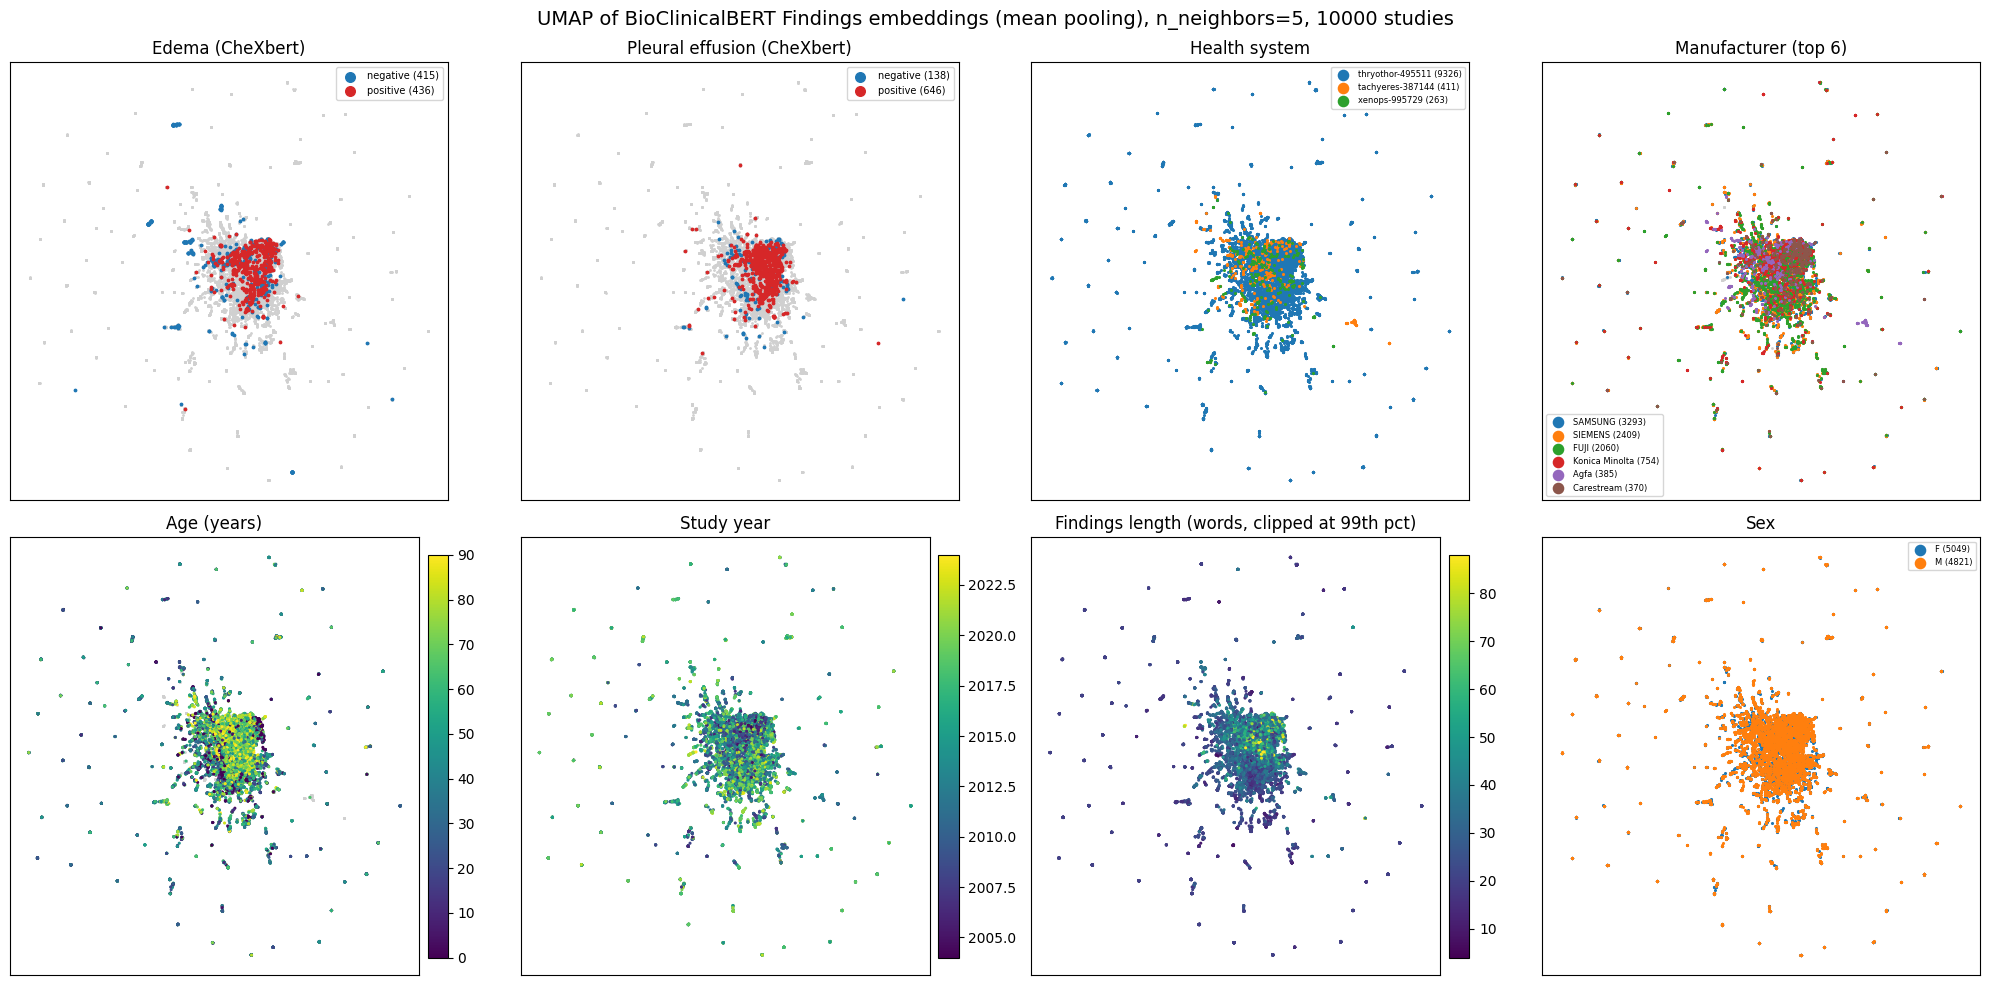

In [ ]:
#N_NEIGHBORS = [5, 15, 200]
FIG_DIR.mkdir(parents=True, exist_ok=True)

studies = study_table()
X = load_embeddings(embedding_path("findings"), studies)
keep = usable_findings(studies).values            # drop empty / very short Findings
s, X = studies[keep].reset_index(drop=True), X[keep]
print(f"{keep.sum()} of {len(keep)} studies have usable Findings")


Z5 = umap_coords(X, 5, tag="findings_mean_layer-1")   # loads from cache if it exists
make_figure(Z5, s, 5, save=False)

- I dunno what to make of the plot above for n=5
- It seems like things are distributed evenly and randomly 


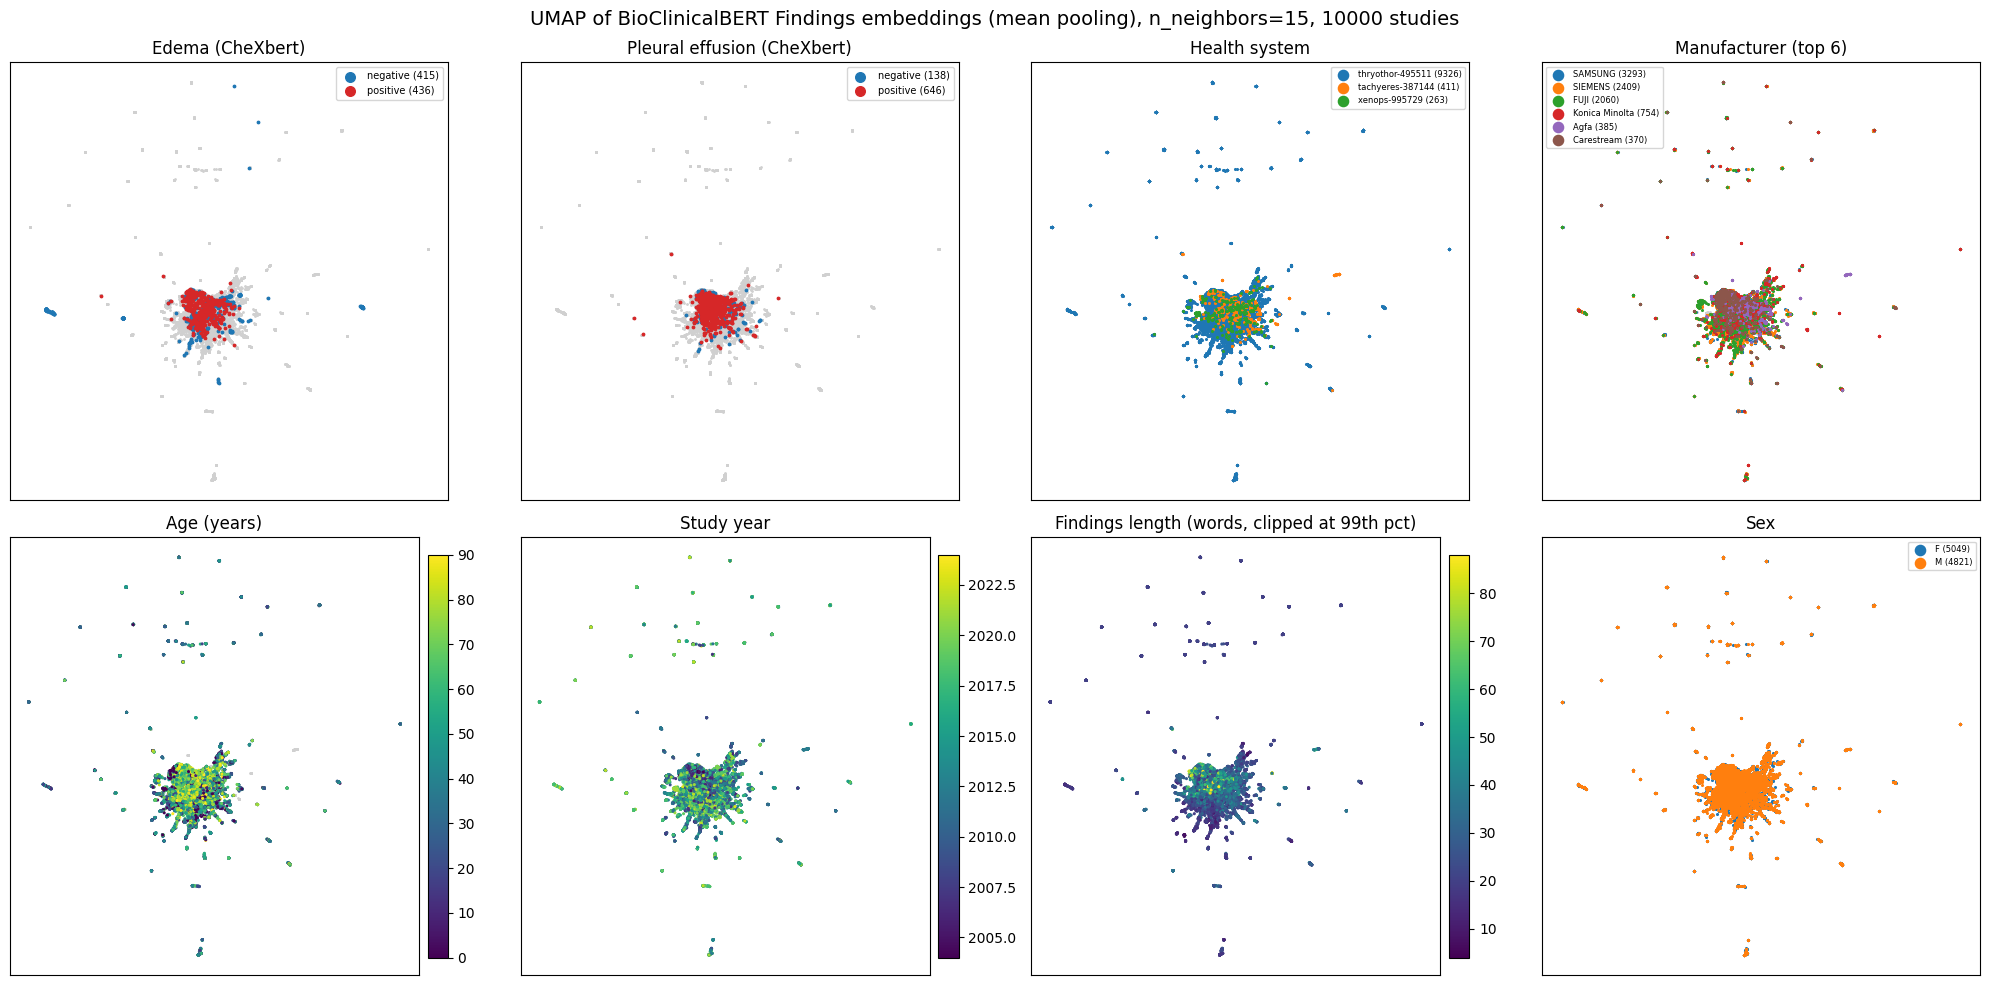

In [ ]:
Z15 = umap_coords(X, 15, tag="findings_mean_layer-1")   # loads from cache if it exists
make_figure(Z15, s, 15, save=False)

- Same here with n=15 as for n=5, nothing intereting to point except that nothing interesting can be pointed out

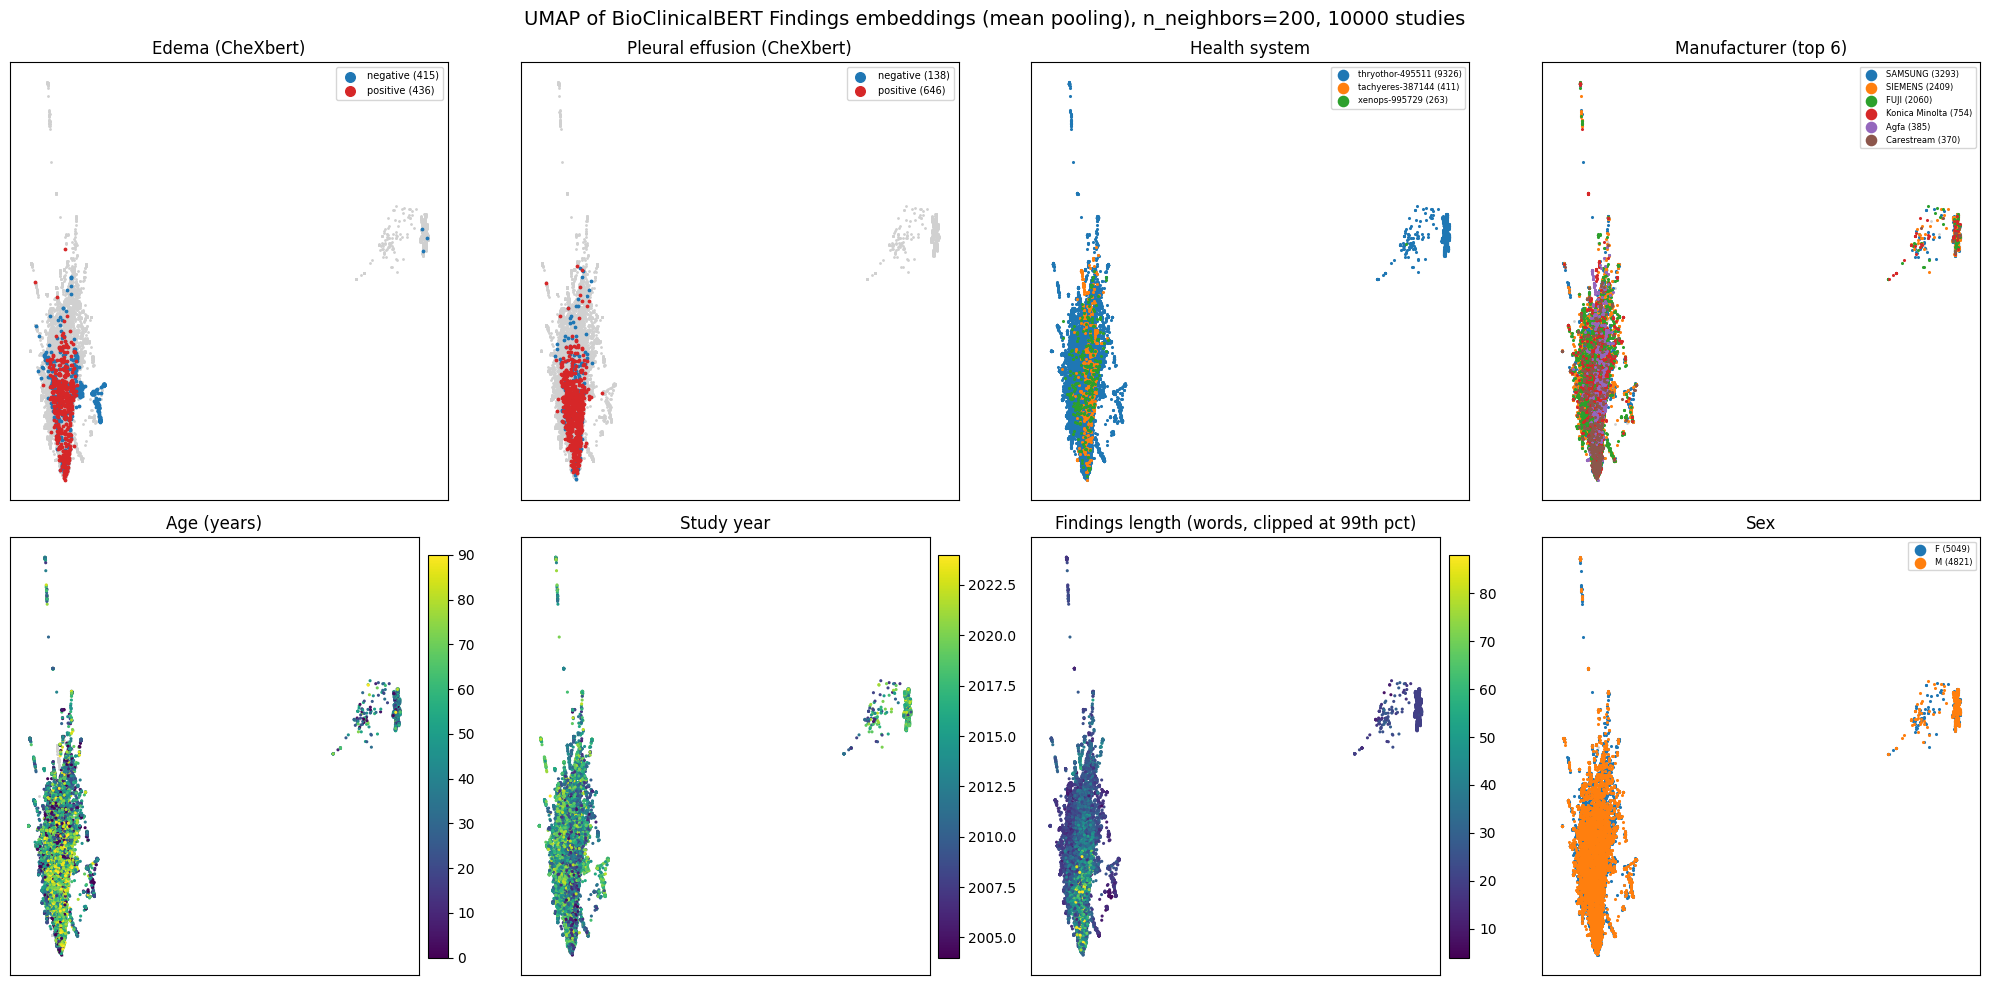

In [ ]:
Z200 = umap_coords(X, 200, tag="findings_mean_layer-1")   # loads from cache if it exists
make_figure(Z200, s, 200, save=False)

- So with the umap we can only make the conclusion that things that close together in the space are more similar
- Nothing can be interpreted about the distance except that we have 2 clusters
- nothing on the axes
- We see an elongated shape and another diffused blob in the right 
- We see positives are concentrated towards the bottom of the elongated shape for both diseases
- And in the same area there is a gradient for the lenght of the report being longer towarss the bottom of the shape, same with age
- With regrads to health system the only thing that sticks out that tachyeres is not present in the cluster on the right
- nothign concpicious with regards to sex or study year o rmanufacture
- based on the means we can differentiate the disease using the age since the higher have more positives 
- base don report length we can disntiguish the disease in edema positive sfrom negatives, but in pleural effusion we can distinguish label from no clear label 

- This simply means the model might lean on this to make its predictions but its not clear that it actually will do this yet 

In [ ]:
from src.data import study_table, binary_label
s = study_table()
for d in ["edema", "pleural_effusion"]:
    g = binary_label(s, d).map({1: "positive", 0: "negative"}).fillna("no clear label")
    table = s.groupby(g)[["findings_words", "age_years"]].agg(["mean", "std"]).round(1)
    table.columns = [f"{col} ({stat})" for col, stat in table.columns]   # flatten to one header row
    table.index.name = f"{d} label"
    print(f"=== {d}: ===")
    print(table, "\n")

=== edema: ===
                findings_words (mean)  findings_words (std)  age_years (mean)  \
edema label                                                                     
negative                         33.7                  19.2              54.7   
no clear label                   31.8                  15.8              45.6   
positive                         41.2                  19.4              67.1   

                age_years (std)  
edema label                      
negative                   24.6  
no clear label             26.1  
positive                   23.6   

=== pleural_effusion: ===
                        findings_words (mean)  findings_words (std)  \
pleural_effusion label                                                
negative                                 42.7                  19.5   
no clear label                           31.4                  15.7   
positive                                 42.9                  19.2   

                        a

| Condition | Label | Findings length (words), mean ± SD | Age (years), mean ± SD |
|---|---|---|---|
| **Edema** | Positive | 41.2 ± 19.4 | 67.1 ± 23.6 |
| | Negative | 33.7 ± 19.2 | 54.7 ± 24.6 |
| | No clear label | 31.8 ± 15.8 | 45.6 ± 26.1 |
| **Pleural effusion** | Positive | 42.9 ± 19.2 | 69.3 ± 18.4 |
| | Negative | 42.7 ± 19.5 | 51.2 ± 28.2 |
| | No clear label | 31.4 ± 15.7 | 45.3 ± 26.1 |

- Using the mean, there is a 12-18 year age gap for positives in the diseases, with std. indicating these overlap as well.
- Length of words only distinguishes between positive and negative in edema and label from no clear label in plerual effusion

## Step 4 - Linear Probe

In [ ]:
# 1. Imports for logistic regression 
import numpy as np
from sklearn.linear_model import LogisticRegression
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import roc_auc_score

In [ ]:
import os, sys
from pathlib import Path

PROJECT = Path.cwd().parent            # notebook folder → its parent = project root (where src/ and data/ are)
os.chdir(PROJECT)                      # so data/... paths in src/data.py work
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))   # so "import src" works

print("working dir:", Path.cwd())      # should end in responsible-ai-rexgradient-main

from src.data import study_table, usable_findings, binary_label, top_k_classes
from src.embeddings import embedding_path, load_embeddings

working dir: c:\Users\lucas\Desktop\4th_semester\02517_responsible_ai\code\mandatory\project3\responsible-ai-rexgradient-main


c:\Users\lucas\Desktop\4th_semester\02517_responsible_ai\code\mandatory\project3\responsible-ai-rexgradient-main\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


- Use the above to import from the src folder (and potentially other folders in the same layer)

In [ ]:
# 2. load embeddings, labels and filter them
studies = study_table()
X = load_embeddings(embedding_path("findings"), studies)

keep = usable_findings(studies).values
s, X = studies[keep].reset_index(drop=True), X[keep]

def clear_cases(disease):
    """X, y and patient ids for one disease, only clear positive/negative studies."""
    label = binary_label(s, disease)
    m = label.notna().values               
    return X[m], label[m].astype(int).values, s.loc[m, "patient_id"].values

X_ed, y_ed, g_ed = clear_cases("edema")
X_ef, y_ef, g_ef = clear_cases("pleural_effusion")
print(X_ed.shape, y_ed.shape)   # (851, 768) (851,)
print(X_ef.shape, y_ef.shape)   # (784, 768) (784,)

(851, 768) (851,)
(784, 768) (784,)


In [ ]:
# 3. Patient-wise 5-fold split for edema
from sklearn.model_selection import StratifiedGroupKFold

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)

for fold, (train_idx, test_idx) in enumerate(cv.split(X_ed, y_ed, groups=g_ed)):
    shared_patients = set(g_ed[train_idx]) & set(g_ed[test_idx])
    print(f"fold {fold}: train {len(train_idx)} studies ({y_ed[train_idx].mean():.0%} positive) | "
          f"test {len(test_idx)} studies ({y_ed[test_idx].mean():.0%} positive) | "
          f"patients in both: {len(shared_patients)}")


fold 0: train 683 studies (52% positive) | test 168 studies (49% positive) | patients in both: 0
fold 1: train 684 studies (50% positive) | test 167 studies (55% positive) | patients in both: 0
fold 2: train 684 studies (51% positive) | test 167 studies (51% positive) | patients in both: 0
fold 3: train 683 studies (51% positive) | test 168 studies (51% positive) | patients in both: 0
fold 4: train 670 studies (51% positive) | test 181 studies (51% positive) | patients in both: 0


- we split the data equally into the folds mainataining the positive/negative ratios. No duplciate patients in traind and test

In [ ]:
# 4. BERT probe for edema: train on 4 folds, predict the 5th, repeat 5 times

probs_ed = np.zeros(len(y_ed))          # one out-of-fold probability per study

for fold, (train_idx, test_idx) in enumerate(cv.split(X_ed, y_ed, groups=g_ed)):
    model = Pipeline([
        ("scale", StandardScaler()),                         # each of the 768 features: mean 0, std 1
        ("clf", LogisticRegression(C=0.1, max_iter=3000)),   # the linear probe
    ])
    model.fit(X_ed[train_idx], y_ed[train_idx])              # learn from 4 folds
    probs_ed[test_idx] = model.predict_proba(X_ed[test_idx])[:, 1]   # P(positive) for the unseen fold
    print(f"fold {fold}: AUROC = {roc_auc_score(y_ed[test_idx], probs_ed[test_idx]):.3f}")

auc_bert_ed = roc_auc_score(y_ed, probs_ed)                  # ONE AUROC over all studies
print(f"\nEdema, BERT probe: AUROC = {auc_bert_ed:.3f}")

fold 0: AUROC = 0.897
fold 1: AUROC = 0.959
fold 2: AUROC = 0.948
fold 3: AUROC = 0.907
fold 4: AUROC = 0.931

Edema, BERT probe: AUROC = 0.928


- AUROC score gives how often the model assigns a higher probability to the true label - prob that a random positive gets a higher rating than a random negative

- The final AUROC score, is the ratio across all test sets from the K folds: every rapport gets one prediction from the model which didn't see it under training. After one AUCROC score is calculated across all predictins

- AUROC is well above equal chance of 0.5, so edema is preent in the representation

- README expects about 0.9



In [ ]:
# 5. TF-IDF probe for edema (same folds, raw Findings text instead of embeddings)
from sklearn.feature_extraction.text import TfidfVectorizer

m_ed = binary_label(s, "edema").notna().values             # same mask as inside clear_cases
texts_ed = s.loc[m_ed, "findings"].fillna("").values       # same 851 rows as X_ed / y_ed
assert len(texts_ed) == len(y_ed)                          # safety check: rows line up

probs_tfidf_ed = np.zeros(len(y_ed))

for fold, (train_idx, test_idx) in enumerate(cv.split(X_ed, y_ed, groups=g_ed)):
    model = Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),  # words + word pairs
        ("clf", LogisticRegression(C=1.0, max_iter=3000)),
    ])
    model.fit(texts_ed[train_idx], y_ed[train_idx])         # vocabulary learned from training folds only
    probs_tfidf_ed[test_idx] = model.predict_proba(texts_ed[test_idx])[:, 1]
    print(f"fold {fold}: AUROC = {roc_auc_score(y_ed[test_idx], probs_tfidf_ed[test_idx]):.3f}")

auc_tfidf_ed = roc_auc_score(y_ed, probs_tfidf_ed)
print(f"\nEdema, TF-IDF probe: AUROC = {auc_tfidf_ed:.3f}   (BERT: {auc_bert_ed:.3f})")

fold 0: AUROC = 0.916
fold 1: AUROC = 0.966
fold 2: AUROC = 0.964
fold 3: AUROC = 0.925
fold 4: AUROC = 0.964

Edema, TF-IDF probe: AUROC = 0.947   (BERT: 0.928)


- Slighltly better than BERT(0.928) and beats bert in every fold

- words counts predct edema as well using TF-IDF

In [ ]:
# 7. Pleural effusion: same as edema (filter, patient-wise split, BERT probe, TF-IDF probe)
m_ef = binary_label(s, "pleural_effusion").notna().values      # clear positive/negative only
X_ef = X[m_ef]
y_ef = binary_label(s, "pleural_effusion")[m_ef].astype(int).values
g_ef = s.loc[m_ef, "patient_id"].values
texts_ef = s.loc[m_ef, "findings"].fillna("").values
print(f"{len(y_ef)} studies: {y_ef.sum()} positive, {(y_ef == 0).sum()} negative, "
      f"{len(set(g_ef))} patients")

probs_bert_ef = np.zeros(len(y_ef))
probs_tfidf_ef = np.zeros(len(y_ef))

for fold, (train_idx, test_idx) in enumerate(cv.split(X_ef, y_ef, groups=g_ef)):
    # BERT probe
    bert = Pipeline([("scale", StandardScaler()),
                     ("clf", LogisticRegression(C=0.1, max_iter=3000))])
    bert.fit(X_ef[train_idx], y_ef[train_idx])
    probs_bert_ef[test_idx] = bert.predict_proba(X_ef[test_idx])[:, 1]

    # TF-IDF probe
    tfidf = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
                      ("clf", LogisticRegression(C=1.0, max_iter=3000))])
    tfidf.fit(texts_ef[train_idx], y_ef[train_idx])
    probs_tfidf_ef[test_idx] = tfidf.predict_proba(texts_ef[test_idx])[:, 1]

    print(f"fold {fold}: BERT {roc_auc_score(y_ef[test_idx], probs_bert_ef[test_idx]):.3f} | "
          f"TF-IDF {roc_auc_score(y_ef[test_idx], probs_tfidf_ef[test_idx]):.3f}")

auc_bert_ef = roc_auc_score(y_ef, probs_bert_ef)
auc_tfidf_ef = roc_auc_score(y_ef, probs_tfidf_ef)
print(f"\nPleural effusion: BERT AUROC = {auc_bert_ef:.3f} | TF-IDF AUROC = {auc_tfidf_ef:.3f}")

784 studies: 646 positive, 138 negative, 607 patients
fold 0: BERT 0.929 | TF-IDF 0.946
fold 1: BERT 0.927 | TF-IDF 0.936
fold 2: BERT 0.966 | TF-IDF 0.970
fold 3: BERT 0.927 | TF-IDF 0.896
fold 4: BERT 0.944 | TF-IDF 0.936

Pleural effusion: BERT AUROC = 0.939 | TF-IDF AUROC = 0.939


- Notice the ratio of pleural effusion positives are different compared to edema

- Effusion is also present in the embeddings above the baseline of 82 % which is the ratio of positives in all studies used.
✗ Chance for AUROC er 0,5. 82 % er bare andelen af positive.

## Step5

In [ ]:
# 8. Step 5: health system (3 classes) - BERT probe vs TF-IDF
from sklearn.metrics import balanced_accuracy_score, confusion_matrix

y_hs = s["health_system"].values                        # 3 classes, every study has one
g_hs = s["patient_id"].values
texts_hs = s["findings"].fillna("").values
X_hs = X                                                # all usable studies
print(pd.Series(y_hs).value_counts(), "\n")

pred_bert_hs = np.empty(len(y_hs), dtype=object)
pred_tfidf_hs = np.empty(len(y_hs), dtype=object)

for fold, (train_idx, test_idx) in enumerate(cv.split(X_hs, y_hs, groups=g_hs)):
    # BERT probe (class_weight="balanced": small hospitals count as much as the big one)
    bert = Pipeline([("scale", StandardScaler()),
                     ("clf", LogisticRegression(C=0.1, max_iter=3000, class_weight="balanced"))])
    bert.fit(X_hs[train_idx], y_hs[train_idx])
    pred_bert_hs[test_idx] = bert.predict(X_hs[test_idx])

    # TF-IDF probe
    tfidf = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
                      ("clf", LogisticRegression(C=1.0, max_iter=3000, class_weight="balanced"))])
    tfidf.fit(texts_hs[train_idx], y_hs[train_idx])
    pred_tfidf_hs[test_idx] = tfidf.predict(texts_hs[test_idx])

    print(f"fold {fold}: BERT {balanced_accuracy_score(y_hs[test_idx], pred_bert_hs[test_idx]):.3f} | "
          f"TF-IDF {balanced_accuracy_score(y_hs[test_idx], pred_tfidf_hs[test_idx]):.3f}")

bacc_bert_hs = balanced_accuracy_score(y_hs, pred_bert_hs)
bacc_tfidf_hs = balanced_accuracy_score(y_hs, pred_tfidf_hs)
print(f"\nHealth system: BERT balanced acc = {bacc_bert_hs:.3f} | TF-IDF = {bacc_tfidf_hs:.3f} | chance = {1/3:.3f}")

# which hospitals get confused with which (rows = true, columns = predicted)
classes = sorted(set(y_hs))
print("\nBERT confusion matrix:")
print(pd.DataFrame(confusion_matrix(y_hs, pred_bert_hs, labels=classes), index=classes, columns=classes))

thryothor-495511    9326
tachyeres-387144     411
xenops-995729        263
Name: count, dtype: int64 

fold 0: BERT 0.812 | TF-IDF 0.855
fold 1: BERT 0.749 | TF-IDF 0.839
fold 2: BERT 0.694 | TF-IDF 0.816
fold 3: BERT 0.715 | TF-IDF 0.824
fold 4: BERT 0.749 | TF-IDF 0.857

Health system: BERT balanced acc = 0.743 | TF-IDF = 0.841 | chance = 0.333

BERT confusion matrix:
                  tachyeres-387144  thryothor-495511  xenops-995729
tachyeres-387144               308                81             22
thryothor-495511               287              8742            297
xenops-995729                   28                92            143


- Both BERT and TF-IDF give an higher accuracy than random chance of 0.33 (more than 2x )

- Confusion matrix should be read as first row is true label, 1st col is predicted values. So the diagonal gives the number of true positives



In [ ]:
# 9. Step 5: manufacturer (6 most frequent brands) - BERT probe vs TF-IDF
manu = top_k_classes(s["manufacturer"], 6)               # other brands -> NaN
m_mf = manu.notna().values                               # keep only the top-6 brands
y_mf = manu[m_mf].values
X_mf = X[m_mf]
g_mf = s.loc[m_mf, "patient_id"].values
texts_mf = s.loc[m_mf, "findings"].fillna("").values
print(pd.Series(y_mf).value_counts(), "\n")

pred_bert_mf = np.empty(len(y_mf), dtype=object)
pred_tfidf_mf = np.empty(len(y_mf), dtype=object)

for fold, (train_idx, test_idx) in enumerate(cv.split(X_mf, y_mf, groups=g_mf)):
    # BERT probe
    bert = Pipeline([("scale", StandardScaler()),
                     ("clf", LogisticRegression(C=0.1, max_iter=3000, class_weight="balanced"))])
    bert.fit(X_mf[train_idx], y_mf[train_idx])
    pred_bert_mf[test_idx] = bert.predict(X_mf[test_idx])

    # TF-IDF probe
    tfidf = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
                      ("clf", LogisticRegression(C=1.0, max_iter=3000, class_weight="balanced"))])
    tfidf.fit(texts_mf[train_idx], y_mf[train_idx])
    pred_tfidf_mf[test_idx] = tfidf.predict(texts_mf[test_idx])

    print(f"fold {fold}: BERT {balanced_accuracy_score(y_mf[test_idx], pred_bert_mf[test_idx]):.3f} | "
          f"TF-IDF {balanced_accuracy_score(y_mf[test_idx], pred_tfidf_mf[test_idx]):.3f}")

bacc_bert_mf = balanced_accuracy_score(y_mf, pred_bert_mf)
bacc_tfidf_mf = balanced_accuracy_score(y_mf, pred_tfidf_mf)
print(f"\nManufacturer: BERT balanced acc = {bacc_bert_mf:.3f} | TF-IDF = {bacc_tfidf_mf:.3f} | chance = {1/6:.3f}")

classes = sorted(set(y_mf))
print("\nBERT confusion matrix (rows = true, columns = predicted):")
print(pd.DataFrame(confusion_matrix(y_mf, pred_bert_mf, labels=classes), index=classes, columns=classes))

SAMSUNG           3293
SIEMENS           2409
FUJI              2060
Konica Minolta     754
Agfa               385
Carestream         370
Name: count, dtype: int64 

fold 0: BERT 0.506 | TF-IDF 0.558
fold 1: BERT 0.477 | TF-IDF 0.560
fold 2: BERT 0.466 | TF-IDF 0.562
fold 3: BERT 0.487 | TF-IDF 0.575
fold 4: BERT 0.483 | TF-IDF 0.543

Manufacturer: BERT balanced acc = 0.483 | TF-IDF = 0.560 | chance = 0.167

BERT confusion matrix (rows = true, columns = predicted):
                Agfa  Carestream  FUJI  Konica Minolta  SAMSUNG  SIEMENS
Agfa             273          14    25              31       19       23
Carestream        14         137    68              32       87       32
FUJI              74         179   854             195      279      479
Konica Minolta    36          52   115             393       96       62
SAMSUNG           52         364   304             145     1815      613
SIEMENS           54         123   475             161      795      801


- We get a blanced accruacy 0.483 for BERT and 0.56 for TF-IDF which is more than 3x from rnadom chance of 1/6=0.167, implying the manufacturer can be read frm the embedding

In [ ]:
# 10. Are manufacturer and site entangled? (share of each brand per health system)
print(pd.crosstab(s["manufacturer"], s["health_system"]).loc[classes])
print()
print("number of hospital sites per brand:")
print(s[s["manufacturer"].isin(classes)].groupby("manufacturer")["institution"].nunique())

health_system   tachyeres-387144  thryothor-495511  xenops-995729
manufacturer                                                     
Agfa                         384                 0              1
Carestream                    13               357              0
FUJI                           0              1946            114
Konica Minolta                 0               754              0
SAMSUNG                        0              3282             11
SIEMENS                        0              2381             28

number of hospital sites per brand:
manufacturer
Agfa               9
Carestream         4
FUJI              19
Konica Minolta     8
SAMSUNG           22
SIEMENS           14
Name: institution, dtype: int64


Agfa findes næsten kun på tachyeres (384 af 385), og tachyeres bruger næsten kun Agfa.
Konica Minolta findes kun på thryothor.

Hvis proben kan se, at en rapport kommer fra tachyeres, kan den derfor også gætte “Agfa”. Man kan ikke vide, om embeddingen faktisk indeholder noget om maskinen, eller om den bare kender hospitalet, og maskinen følger med. De to er filtret sammen (confounded).

In [ ]:
# 12. Step 5: sex (F vs M) - BERT probe vs TF-IDF, AUROC
sex = s["sex"].map({"F": 1, "M": 0})                     # 'O' (130 studies) -> NaN, dropped
m_sx = sex.notna().values
y_sx = sex[m_sx].astype(int).values
X_sx = X[m_sx]
g_sx = s.loc[m_sx, "patient_id"].values
texts_sx = s.loc[m_sx, "findings"].fillna("").values
print(f"{len(y_sx)} studies: {y_sx.sum()} F, {(y_sx == 0).sum()} M\n")

probs_bert_sx = np.zeros(len(y_sx))
probs_tfidf_sx = np.zeros(len(y_sx))

for fold, (train_idx, test_idx) in enumerate(cv.split(X_sx, y_sx, groups=g_sx)):
    bert = Pipeline([("scale", StandardScaler()),
                     ("clf", LogisticRegression(C=0.1, max_iter=3000))])
    bert.fit(X_sx[train_idx], y_sx[train_idx])
    probs_bert_sx[test_idx] = bert.predict_proba(X_sx[test_idx])[:, 1]

    tfidf = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
                      ("clf", LogisticRegression(C=1.0, max_iter=3000))])
    tfidf.fit(texts_sx[train_idx], y_sx[train_idx])
    probs_tfidf_sx[test_idx] = tfidf.predict_proba(texts_sx[test_idx])[:, 1]

    print(f"fold {fold}: BERT {roc_auc_score(y_sx[test_idx], probs_bert_sx[test_idx]):.3f} | "
          f"TF-IDF {roc_auc_score(y_sx[test_idx], probs_tfidf_sx[test_idx]):.3f}")

auc_bert_sx = roc_auc_score(y_sx, probs_bert_sx)
auc_tfidf_sx = roc_auc_score(y_sx, probs_tfidf_sx)
print(f"\nSex: BERT AUROC = {auc_bert_sx:.3f} | TF-IDF AUROC = {auc_tfidf_sx:.3f} | chance = 0.500")

9870 studies: 5049 F, 4821 M

fold 0: BERT 0.542 | TF-IDF 0.566
fold 1: BERT 0.550 | TF-IDF 0.568
fold 2: BERT 0.542 | TF-IDF 0.558
fold 3: BERT 0.540 | TF-IDF 0.537
fold 4: BERT 0.557 | TF-IDF 0.575

Sex: BERT AUROC = 0.546 | TF-IDF AUROC = 0.560 | chance = 0.500


- AUROC for BERT and TF-IDF are both near 50 % meaning both embeddings do not strongly have the sexes implied 

- TF-IDF being slightly better could hint a words that imply that distinguishes the biological sexes

## Step 6

- What does the probe find that the UMAP picture does not show, or the other way round?
    - From the UMAP no clear patterns emerge from the health system and manufacture. Yet with the probe we get higher balanced accruacy for both health system and manufacture compared to chance, indicating these are encoded in the embeddings



- Where do TF-IDF and BioClinicalBERT differ, and why?
    - TF-IDF matches or beats BERT on every target. Mostly observed in the non disease targets so health system and manufature

    - BERT Pools the word in the reports into one vector whereas TF-IDF accounts for every word present in the reports and uses them for the features

    - Health systems or hospitals use probably specific patterns of phrase which is what the word count in tf-idf picks up

- What could the presence of the metadata you found mean for a model built on this representation?

    - Since the model can distinguish between manufacture and health systems it might learn that some of these have higher association with the disease than others and assign probabilities based on this. THis give spoor generalisation to new hospitals or different equipment use. 

    - Further from the UMAP it was also observed disaease is linked with age  and report length 

## Nice To have

In [ ]:
sns.set(style='white', context='notebook', rc={'figure.figsize':(14,10)})
sns.pairplot(penguins.drop("year", axis=1), hue='species');